# Movie Recommendation System with Machine Learning

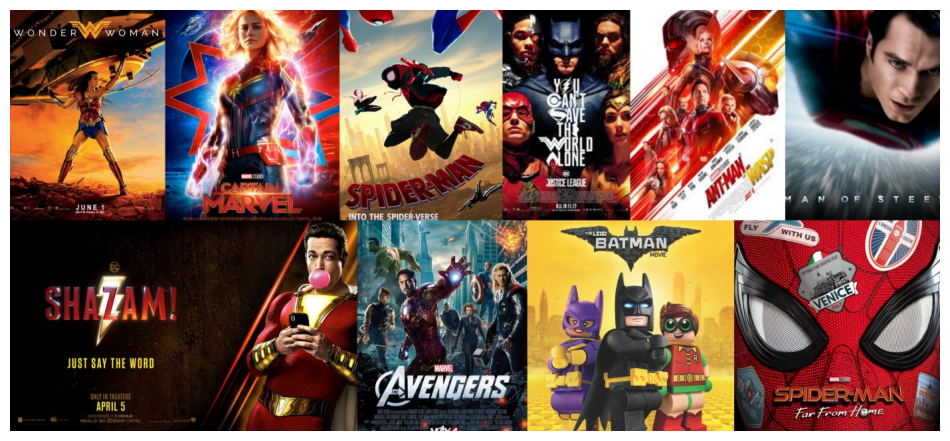

In [4]:
import matplotlib.pyplot as plt
import requests
from PIL import Image
import io

# Resim URL'sini buraya girin
image_url = "https://i0.wp.com/thecleverprogrammer.com/wp-content/uploads/2020/06/Untitled.jpg?w=1400&ssl=1"

# Resmi indir
response = requests.get(image_url)
image = Image.open(io.BytesIO(response.content))

# Resmi göster
plt.figure(figsize=(12, 8))
plt.imshow(image)
plt.axis('off')
plt.show()

Kendi öneri sistemimizi kuralım
Bu Veri Bilimi projesinde, basit ve içerik tabanlı öneri sistemlerinin temel bir modelinin nasıl oluşturulacağını göreceksiniz.

Bu modeller karmaşıklık, kalite veya doğruluk açısından endüstri standardına yakın olmasa da, daha iyi sonuçlar üreten daha karmaşık modeller oluşturmaya başlamanıza yardımcı olacaktır.

In [5]:
import pandas as pd
import numpy as np
credits = pd.read_csv("tmdb_5000_credits.csv")
movies = pd.read_csv("tmdb_5000_movies.csv")
credits.head()

,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,206647,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."
3,49026,The Dark Knight Rises,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de..."
4,49529,John Carter,"[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de..."


In [6]:
movies.head()

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124


In [7]:
print("Credits:",credits.shape)
print("Movies Dataframe:",movies.shape)

Credits: (4803, 4)
Movies Dataframe: (4803, 20)


In [8]:
credits_column_renamed = credits.rename(index=str, columns={"movie_id": "id"})
movies_merge = movies.merge(credits_column_renamed, on='id')
print(movies_merge.head())

      budget                                             genres  \
0  237000000  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   
1  300000000  [{"id": 12, "name": "Adventure"}, {"id": 14, "...   
2  245000000  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   
3  250000000  [{"id": 28, "name": "Action"}, {"id": 80, "nam...   
4  260000000  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   

                                       homepage      id  \
0                   http://www.avatarmovie.com/   19995   
1  http://disney.go.com/disneypictures/pirates/     285   
2   http://www.sonypictures.com/movies/spectre/  206647   
3            http://www.thedarkknightrises.com/   49026   
4          http://movies.disney.com/john-carter   49529   

                                            keywords original_language  \
0  [{"id": 1463, "name": "culture clash"}, {"id":...                en   
1  [{"id": 270, "name": "ocean"}, {"id": 726, "na...                en   
2  [{"id": 470, "nam

In [9]:
movies_cleaned = movies_merge.drop(columns=['homepage', 'title_x', 'title_y', 'status','production_countries'])
print(movies_cleaned.head())
print(movies_cleaned.info())
print(movies_cleaned.head(1)['overview'])

      budget                                             genres      id  \
0  237000000  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   19995   
1  300000000  [{"id": 12, "name": "Adventure"}, {"id": 14, "...     285   
2  245000000  [{"id": 28, "name": "Action"}, {"id": 12, "nam...  206647   
3  250000000  [{"id": 28, "name": "Action"}, {"id": 80, "nam...   49026   
4  260000000  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   49529   

                                            keywords original_language  \
0  [{"id": 1463, "name": "culture clash"}, {"id":...                en   
1  [{"id": 270, "name": "ocean"}, {"id": 726, "na...                en   
2  [{"id": 470, "name": "spy"}, {"id": 818, "name...                en   
3  [{"id": 849, "name": "dc comics"}, {"id": 853,...                en   
4  [{"id": 818, "name": "based on novel"}, {"id":...                en   

                             original_title  \
0                                    Avatar   
1  Pirates

Şimdi genel bakış sütununda verilen film özetlerine dayanarak önerilerde bulunalım. Yani kullanıcımız bize bir film adı verirse, amacımız benzer özetleri paylaşan filmleri önermektir.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfv = TfidfVectorizer(min_df=3,  max_features=None,
            strip_accents='unicode', analyzer='word',token_pattern=r'\w{1,}',
            ngram_range=(1, 3),
            stop_words = 'english')

In [14]:
print(movies_cleaned['overview'].isna().sum())

3


In [15]:
movies_cleaned = movies_cleaned.dropna(subset=['overview'])

In [16]:
# Fitting the TF-IDF on the 'overview' text
tfv_matrix = tfv.fit_transform(movies_cleaned['overview'])
print(tfv_matrix)
print(tfv_matrix.shape)

  (0, 147)	0.3091356637175625
  (0, 1514)	0.2011829330953397
  (0, 5658)	0.26104797828891285
  (0, 2634)	0.28189876819471266
  (0, 5972)	0.2747345275641027
  (0, 6543)	0.2959141439419381
  (0, 9717)	0.24435239113511667
  (0, 5907)	0.17991944361394238
  (0, 9393)	0.24144035289623844
  (0, 3582)	0.21787852024913595
  (0, 6447)	0.2566774187772771
  (0, 7055)	0.2686772484190883
  (0, 431)	0.21084290341291437
  (0, 1670)	0.278153599084312
  (0, 148)	0.3091356637175625
  (1, 1408)	0.2533089650341721
  (1, 5397)	0.21777184036115407
  (1, 973)	0.3197861920916969
  (1, 2318)	0.2189172684598073
  (1, 1806)	0.21045468005671297
  (1, 5263)	0.13328606710757793
  (1, 4205)	0.3080323897734429
  (1, 2872)	0.3232521707896168
  (1, 2848)	0.2155618555572584
  (1, 9609)	0.3355227663181717
  :	:
  (4799, 5303)	0.14458910213097395
  (4799, 3238)	0.16239170968496355
  (4799, 6989)	0.12818526800509908
  (4799, 2754)	0.11415534350193002
  (4799, 8137)	0.12006809459398542
  (4799, 1252)	0.1517332030269128
  (47

In [21]:
import joblib  # veya import pickle

# TF-IDF modelini kaydet
joblib.dump(tfv, 'tfidf_model.pkl')  # joblib ile kaydetme

# Alternatif olarak, pickle kullanarak kaydedebilirsiniz:
# with open('tfidf_model.pkl', 'wb') as f:
#     pickle.dump(tfv, f)

['tfidf_model.pkl']

In [17]:
from sklearn.metrics.pairwise import sigmoid_kernel

# Compute the sigmoid kernel
sig = sigmoid_kernel(tfv_matrix, tfv_matrix)
print(sig[0])

[0.76163447 0.76159416 0.76159416 ... 0.76159416 0.76159416 0.76159416]


### Dizinlerin ve film başlıklarının ters eşlenmesi

In [18]:
# Reverse mapping of indices and movie titles
indices = pd.Series(movies_cleaned.index, index=movies_cleaned['original_title']).drop_duplicates()
print(indices)
print(indices['Newlyweds'])
print(sig[4799])
print(list(enumerate(sig[indices['Newlyweds']])))
print(sorted(list(enumerate(sig[indices['Newlyweds']])), key=lambda x: x[1], reverse=True))

original_title
Avatar                                         0
Pirates of the Caribbean: At World's End       1
Spectre                                        2
The Dark Knight Rises                          3
John Carter                                    4
                                            ... 
El Mariachi                                 4798
Newlyweds                                   4799
Signed, Sealed, Delivered                   4800
Shanghai Calling                            4801
My Date with Drew                           4802
Length: 4800, dtype: int64
4799
[0.76159416 0.76159416 0.76159455 ... 0.76159473 0.76159461 0.76163447]
[(0, 0.7615941559557649), (1, 0.7615941559557649), (2, 0.7615945514025758), (3, 0.7615961598911568), (4, 0.7615949035603545), (5, 0.7615946497300937), (6, 0.7615955508633212), (7, 0.7615944943703276), (8, 0.7615953698958088), (9, 0.7615952974908614), (10, 0.7615945090166364), (11, 0.7615941559557649), (12, 0.7615941559557649), (13, 0.761594

In [19]:
def give_recomendations(title, sig=sig):
    # Get the index corresponding to original_title
    idx = indices[title]

    # Get the pairwsie similarity scores
    sig_scores = list(enumerate(sig[idx]))

    # Sort the movies
    sig_scores = sorted(sig_scores, key=lambda x: x[1], reverse=True)

    # Scores of the 10 most similar movies
    sig_scores = sig_scores[1:11]

    # Movie indices
    movie_indices = [i[0] for i in sig_scores]

    # Top 10 most similar movies
    return movies_cleaned['original_title'].iloc[movie_indices]

İçerik tabanlı öneri sistemimizi öncü film Spy Kids ile test ediyoruz

In [20]:
print(give_recomendations('Avatar'))

1341                Obitaemyy Ostrov
634                       The Matrix
3604                       Apollo 18
2130                    The American
775                        Supernova
529                 Tears of the Sun
151                          Beowulf
311     The Adventures of Pluto Nash
847                         Semi-Pro
942                 The Book of Life
Name: original_title, dtype: object
